<a href="https://colab.research.google.com/github/Sakya0407/Excel-Project-/blob/main/Lab-01-Machine-Learning/notebook/Lab-01-Sentiment-Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 1 - Sentiment Analysis


In [ ]:
import io, re, zipfile, urllib.request
from collections import Counter
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

nltk.download("stopwords", quiet=True)
STOP = set(stopwords.words("english"))

In [ ]:
URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
frames = []
for name in z.namelist():
    if name.endswith("_labelled.txt") and "__MACOSX" not in name:
        frames.append(pd.read_csv(z.open(name), sep="\t", header=None,
                                  names=["text", "label"], quoting=3))
df = pd.concat(frames, ignore_index=True)
print(df.shape, df.label.value_counts().to_dict())

(3000, 2) {0: 1500, 1: 1500}


In [ ]:
#Preprocess
def clean(t):
    t = t.lower()
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()
df["clean_text"] = df.text.apply(clean)
print(df[["text", "clean_text"]].head(5).to_string())

                                                                                 text                                                                         clean_text
0  So there is no way for me to plug it in here in the US unless I go by a converter.  so there is no way for me to plug it in here in the us unless i go by a converter
1                                                         Good case, Excellent value.                                                          good case excellent value
2                                                              Great for the jawbone.                                                              great for the jawbone
3     Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!         tied to charger for conversations lasting more than minutes major problems
4                                                                   The mic is great.                                                                   the


Positive:
 ['Good case, Excellent value.', 'Great for the jawbone.', 'The mic is great.']
Negative:
 ['So there is no way for me to plug it in here in the US unless I go by a converter.', 'Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!', 'I have to jiggle the plug to get it to line up right to get decent volume.']
Top positive: [('great', 201), ('good', 178), ('film', 105), ('phone', 88), ('movie', 86), ('one', 76), ('well', 68), ('best', 63), ('food', 60), ('place', 58)]
Top negative: [('bad', 100), ('movie', 96), ('phone', 80), ('one', 70), ('like', 69), ('food', 66), ('time', 62), ('would', 59), ('film', 58), ('place', 56)]


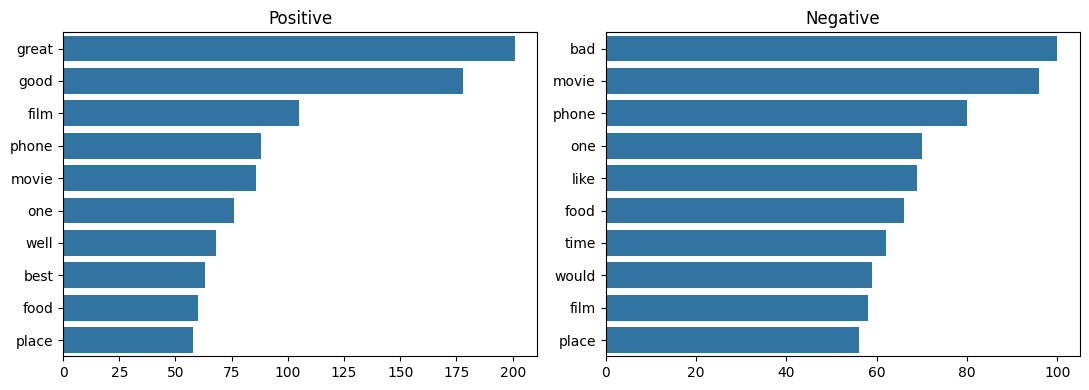

In [ ]:
#Explore
print("\nPositive:\n", df[df.label == 1].text.head(3).tolist())
print("Negative:\n", df[df.label == 0].text.head(3).tolist())
def top_words(label, n=10):
    words = " ".join(df[df.label == label].clean_text).split()
    return Counter(w for w in words if w not in STOP).most_common(n)
pos, neg = top_words(1), top_words(0)
print("Top positive:", pos); print("Top negative:", neg)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, data, t in zip(ax, (pos, neg), ("Positive", "Negative")):
    sns.barplot(x=[c for _, c in data], y=[w for w, _ in data], ax=a); a.set_title(t)
plt.tight_layout(); plt.savefig("lab1_top_words.png")

In [ ]:
#Split
X_tr, X_te, y_tr, y_te = train_test_split(df.clean_text, df.label, test_size=0.2,
                                          random_state=42, stratify=df.label)

In [ ]:
#BoW
vec = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
Xtr, Xte = vec.fit_transform(X_tr), vec.transform(X_te)


LogisticRegression: acc=0.797 prec=0.795 rec=0.800 f1=0.797

LinearSVC: acc=0.772 prec=0.762 rec=0.790 f1=0.776


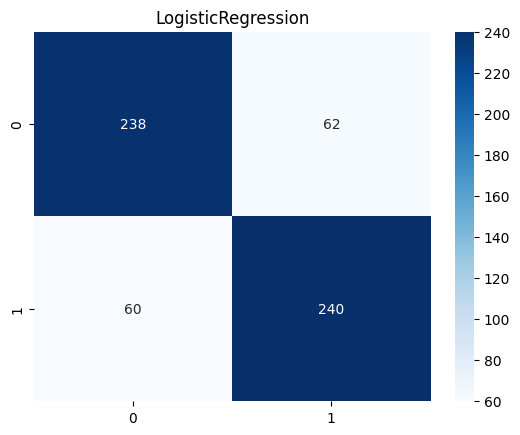

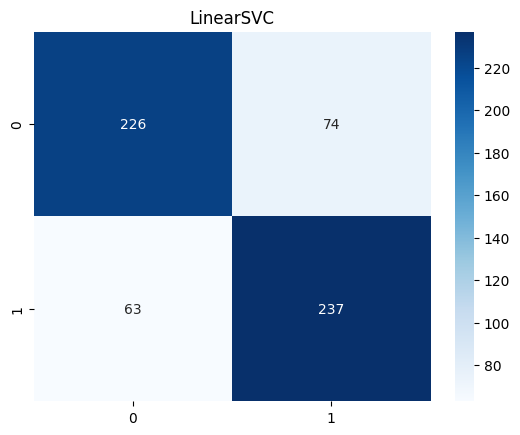

In [ ]:
#Train + evaluate
models = {"LogisticRegression": LogisticRegression(max_iter=1000), "LinearSVC": LinearSVC()}
for name, m in models.items():
    m.fit(Xtr, y_tr); p = m.predict(Xte)
    print(f"\n{name}: acc={accuracy_score(y_te,p):.3f} prec={precision_score(y_te,p):.3f} "
          f"rec={recall_score(y_te,p):.3f} f1={f1_score(y_te,p):.3f}")
    plt.figure(); sns.heatmap(confusion_matrix(y_te, p), annot=True, fmt="d", cmap="Blues")
    plt.title(name); plt.savefig(f"lab1_cm_{name}.png")

In [ ]:
#New sentences
best = models["LogisticRegression"]
for s in ["The battery life is amazing, totally worth it!", "Terrible service, I want a refund."]:
    print(s, "->", "Positive" if best.predict(vec.transform([clean(s)]))[0] else "Negative")

The battery life is amazing, totally worth it! -> Positive
Terrible service, I want a refund. -> Negative
